Name: Kushi Niranjana

SRN: PES2UG24CS245

# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

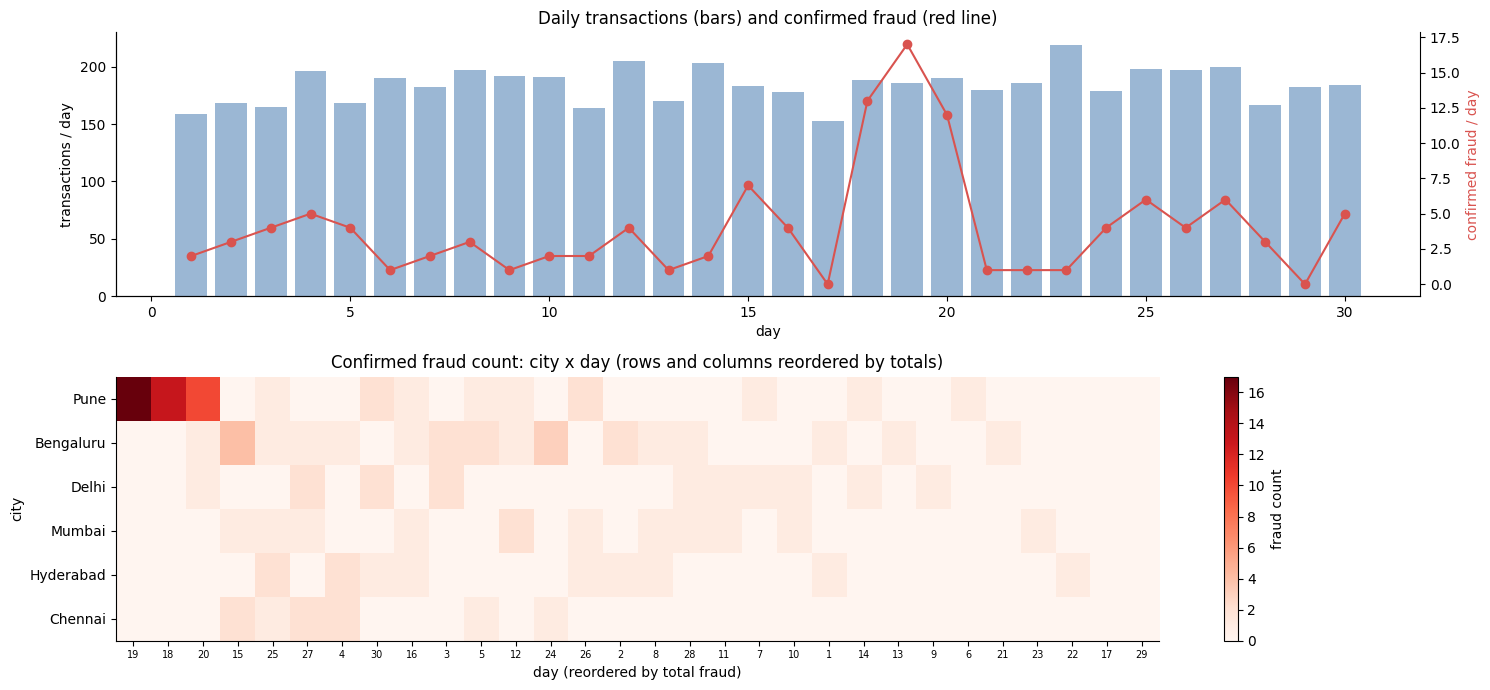

city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
dtype: int64


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1
daily_n = tx.groupby("day").size()
daily_f = tx.groupby("day").is_fraud.sum()
axes[0].bar(daily_n.index, daily_n.values, color="#9bb7d4", label="transactions")
axes[0].set_xlabel("day"); axes[0].set_ylabel("transactions / day")
ax2 = axes[0].twinx()
ax2.plot(daily_f.index, daily_f.values, "-o", color="#D9534F", label="confirmed fraud")
ax2.set_ylabel("confirmed fraud / day", color="#D9534F"); ax2.spines["right"].set_visible(True)
axes[0].set_title("Daily transactions (bars) and confirmed fraud (red line)")

# TODO 2
heat = tx.pivot_table(index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0)
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index,
                heat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat, cmap="Reds", aspect="auto")
axes[1].set_yticks(range(len(heat))); axes[1].set_yticklabels(heat.index)
axes[1].set_xticks(range(len(heat.columns))); axes[1].set_xticklabels(heat.columns, fontsize=7)
axes[1].set_xlabel("day (reordered by total fraud)"); axes[1].set_ylabel("city")
axes[1].set_title("Confirmed fraud count: city x day (rows and columns reordered by totals)")
plt.colorbar(im, ax=axes[1], label="fraud count")

plt.tight_layout(); plt.show()

# TODO 3
print(heat.stack().sort_values(ascending=False).head(5))

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_

The overview showed a hotspot: one city (Pune) on three consecutive days (18–20) carries far more fraud than any other cell. A list sorted by detector score ranks individual transactions, so it would never show that they cluster in one place and time. I found it by reordering the matrix (Slide 39), which pushed the hot cells into one corner so the pattern popped out.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

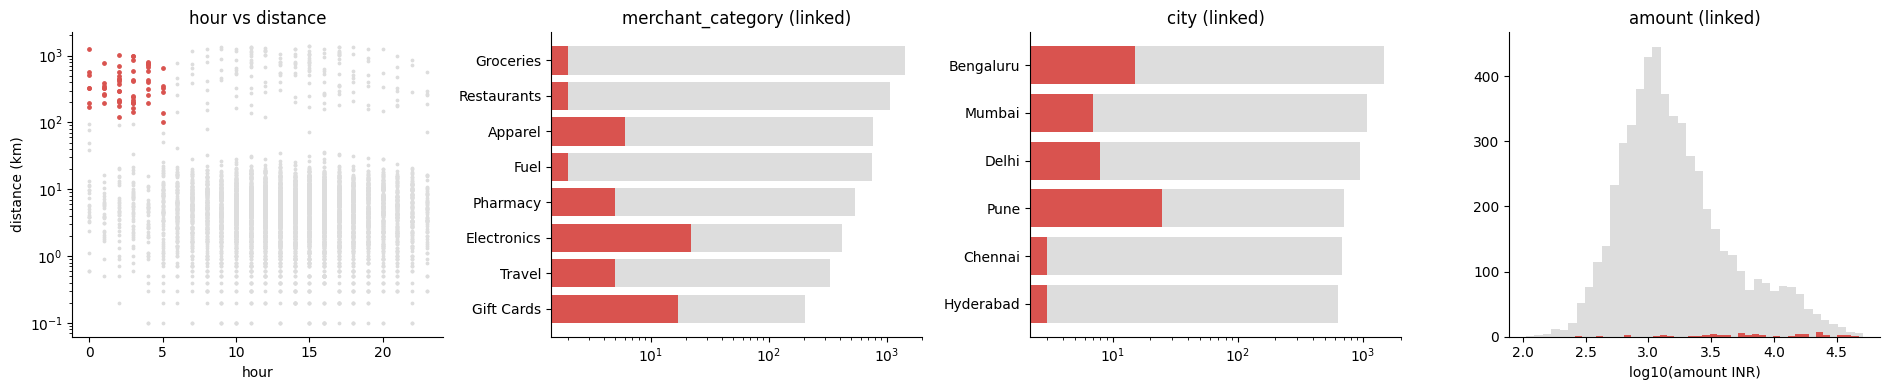

Brushed: 61 | fraud rate inside 86.9% vs overall 2.2% | captures 44% of all fraud (53/120)


In [3]:
# TODO 1
brush = tx.night & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
axes[0].scatter(tx.hour[~brush], tx.distance_from_home_km[~brush], s=3, c="#dddddd")
axes[0].scatter(tx.hour[brush], tx.distance_from_home_km[brush], s=6, c="#D9534F")
axes[0].set_yscale("log"); axes[0].set_xlabel("hour"); axes[0].set_ylabel("distance (km)")
axes[0].set_title("hour vs distance")
for ax, col in zip(axes[1:3], ["merchant_category", "city"]):
    allc = tx[col].value_counts()
    bc = tx.loc[brush, col].value_counts().reindex(allc.index, fill_value=0)
    ax.barh(allc.index, allc.values, color="#dddddd"); ax.barh(bc.index, bc.values, color="#D9534F")
    ax.invert_yaxis(); ax.set_xscale("log"); ax.set_title(f"{col} (linked)")
axes[3].hist(np.log10(tx.amount_inr), bins=40, color="#dddddd")
axes[3].hist(np.log10(tx.amount_inr[brush]), bins=40, color="#D9534F")
axes[3].set_xlabel("log10(amount INR)"); axes[3].set_title("amount (linked)")

plt.tight_layout(); plt.show()

# TODO 3
overall = tx.is_fraud.mean()
inside = tx.is_fraud[brush].mean()
captured = tx.is_fraud[brush].sum() / tx.is_fraud.sum()
print(f"Brushed: {brush.sum()} | fraud rate inside {inside:.1%} vs overall {overall:.1%} | "
      f"captures {captured:.0%} of all fraud ({tx.is_fraud[brush].sum()}/{tx.is_fraud.sum()})")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_

The rule is very precise (87% fraud) but it only catches 44% of all fraud, so over half the fraud happens outside “night + far from home”. Relying on it alone would miss most of the problem. The linked city and merchant-category views hinted at where the rest is: Pune stands out in the city bars, and Electronics and Gift Cards dominate the category bars.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
times = []
for _ in range(5):
    t0 = time.perf_counter()
    _ = big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
    times.append(time.perf_counter() - t0)
best_s = min(times)

# TODO 2
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (best_s / len(big))

# TODO 3
t_50m = 50_000_000 * best_s / len(big)
skip_pct = max(0, (1 - 0.1 / t_50m) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 18.1 ms -> 0.0180 us/row -> max 5,559,913 rows in 0.1 s
50M rows -> 0.90 s; must skip 88.9% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_

One reduce technique is aggregation (or sampling): pre-compute counts per hour/city/category, or filter a sample, so the slider works on thousands of rows instead of 50 million. The analyst loses individual transaction detail, and with fraud at only about 2%, a sample could drop the very needles they are looking for.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

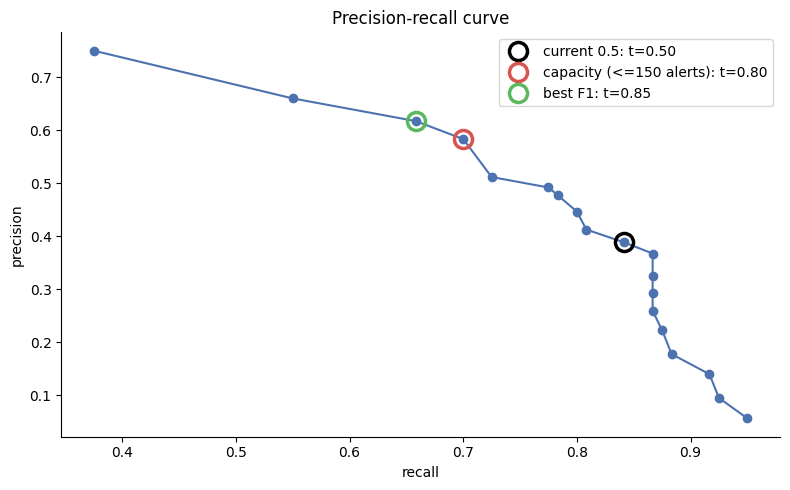

Recommendation: use threshold 0.80 (144 alerts, precision 58%, recall 70%); best-F1 would be 0.85 (128 alerts, F1 0.64).


In [5]:
rows = []
# TODO 1
for th in np.round(np.arange(0.05, 1.0, 0.05), 2):
    flag = tx.detector_score >= th
    tp = int((flag & (tx.is_fraud == 1)).sum())
    fp = int((flag & (tx.is_fraud == 0)).sum())
    fn = int((~flag & (tx.is_fraud == 1)).sum())
    p = tp / (tp + fp) if tp + fp else 0
    r = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * p * r / (p + r) if p + r else 0
    rows.append(dict(threshold=th, alerts=tp + fp, TP=tp, FP=fp, FN=fn,
                     precision=p, recall=r, F1=f1))

pr = pd.DataFrame(rows)

# TODO 2
ok = pr[pr.alerts <= 150]
capacity_choice = ok.loc[ok.recall.idxmax()]
best_f1 = pr.loc[pr.F1.idxmax()]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "o-", color="#4C72B0")
cur = pr[pr.threshold == 0.5].iloc[0]
for pt, name, col in [(cur, "current 0.5", "black"),
                      (capacity_choice, "capacity (<=150 alerts)", "#D9534F"),
                      (best_f1, "best F1", "#5cb85c")]:
    ax.plot(pt.recall, pt.precision, "o", ms=13, mfc="none", mec=col, mew=2.5,
            label=f"{name}: t={pt.threshold:.2f}")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("Precision-recall curve"); ax.legend()

plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommendation: use threshold {capacity_choice.threshold:.2f} "
      f"({int(capacity_choice.alerts)} alerts, precision {capacity_choice.precision:.0%}, recall {capacity_choice.recall:.0%}); "
      f"best-F1 would be {best_f1.threshold:.2f} ({int(best_f1.alerts)} alerts, F1 {best_f1.F1:.2f}).")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_

The Head of Fraud Ops should make that call, not the model. The model can only say how precision and recall trade off. Deciding how many missed frauds are acceptable against how many customers and investigator hours are burned is a business judgement the model can’t make. Visual analytics keeps the human in the loop so they steer the threshold, see the effect immediately, and can challenge the model.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1
flagged = None

# TODO 1
flagged = tx[tx.detector_score >= 0.3]
fig = px.scatter(flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
                 color_discrete_map={"legitimate": "#4C72B0", "confirmed fraud": "#D9534F"},
                 hover_name="txn_id",
                 hover_data={"customer_id": True, "city": True, "merchant_category": True,
                             "distance_from_home_km": ":.0f", "detector_score": ":.3f", "label": False},
                 title="Flagged transactions (score >= 0.3): hover for details, drag to select",
                 height=460)
fig.update_traces(marker_size=7)
fig.update_layout(dragmode="select")
fig.show()

# TODO 2
agg = tx.groupby(["city", "merchant_category"]).agg(transactions=("txn_id", "size"),
                                                     fraud=("is_fraud", "sum")).reset_index()
agg["fraud_rate_pct"] = agg.fraud / agg.transactions * 100
fig = px.sunburst(agg, path=[px.Constant("All cities"), "city", "merchant_category"],
                  values="transactions", color="fraud_rate_pct",
                  color_continuous_scale="Reds", range_color=[0, 25],
                  hover_data={"fraud": True},
                  title="Drill-down: click a city, then its categories", height=560)
fig.show()
# TODO 2

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_

A tooltip shows one case at a time, so getting an overview of 400 cases means hovering 400 times and remembering each one. That is slow and easy to get wrong. The city × day heatmap (or the linked views) fixes it, since it shows all cases at once and the investigator can then hover just the interesting ones.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Fraud rate inside window: 37.4% vs outside: 1.5% (chi-square p = 1.1e-136)
(a) Pune on other days: 1.9%
(b) Other cities on days 18-20: 0.4%


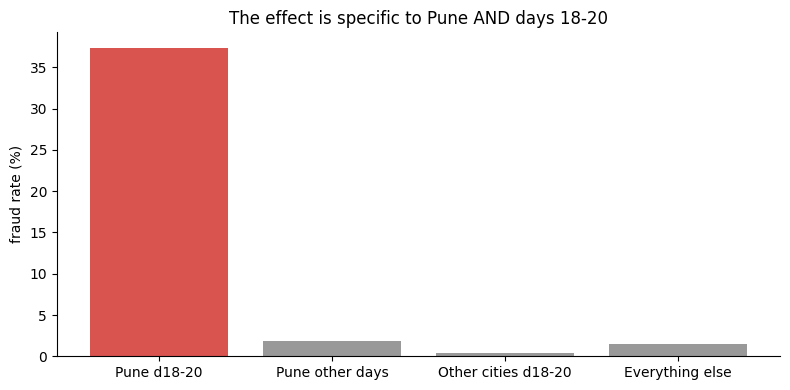

Verdict: hypothesis SUPPORTED - fraud is concentrated in Pune on days 18-20 only; both counter-examples sit near the baseline.


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask (Pune, days 18-20)
in_window = (tx.city == "Pune") & tx.day.between(18, 20)

# TODO 2
table = pd.crosstab(in_window, tx.is_fraud)
chi2, pval, _, _ = chi2_contingency(table)
print(f"Fraud rate inside window: {tx.is_fraud[in_window].mean():.1%} vs outside: "
      f"{tx.is_fraud[~in_window].mean():.1%} (chi-square p = {pval:.1e})")

# TODO 3
pune_other = tx[(tx.city == "Pune") & ~tx.day.between(18, 20)]
others_same = tx[(tx.city != "Pune") & tx.day.between(18, 20)]
rest = tx[(tx.city != "Pune") & ~tx.day.between(18, 20)]
print(f"(a) Pune on other days: {pune_other.is_fraud.mean():.1%}")
print(f"(b) Other cities on days 18-20: {others_same.is_fraud.mean():.1%}")

# TODO 4
fig, ax = plt.subplots(figsize=(8, 4))
grp = {"Pune d18-20": tx.is_fraud[in_window].mean(),
       "Pune other days": pune_other.is_fraud.mean(),
       "Other cities d18-20": others_same.is_fraud.mean(),
       "Everything else": rest.is_fraud.mean()}
ax.bar(grp.keys(), np.array(list(grp.values())) * 100,
       color=["#D9534F", "#999999", "#999999", "#999999"])
ax.set_ylabel("fraud rate (%)")
ax.set_title("The effect is specific to Pune AND days 18-20")

plt.tight_layout(); plt.show()

# TODO 5
print("Verdict: hypothesis SUPPORTED - fraud is concentrated in Pune on days 18-20 only; "
      "both counter-examples sit near the baseline.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_

Either search could have killed it. If Pune on other days had also been high, the explanation would be “Pune just has more fraud in general” (a standing local problem, not a ring). If other cities on days 18-20 had also been high, it would point to something affecting those days everywhere, like a data breach or a detector glitch. Both stayed near the baseline, so the “specific city and specific days” idea survives.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

Last month 120 of 5,520 transactions (2.2%) were confirmed fraud, and a third of them (40) hit Pune on days 18–20, where 37% of transactions were fraud against 1.5% elsewhere. I recommend raising the threshold from 0.5 (260 alerts, over capacity) to 0.80, which gives 144 alerts at 58% precision and 70% recall. The best-F1 value (0.85) is almost identical, but 0.80 uses the team’s full capacity and the final call stays with you, as the human steering the model. The first interactive view to build is the city × day overview linked to filters and tooltips, because overview first lets investigators spot clusters like this one before looking at single alerts. The feedback loop is to feed every confirmed or rejected case back to retrain the detector, so next month’s version improves.